# A4 (Pro版)：交叉口左转让行场景 (LTAP-OD) —— 状态机让行决策与纯追踪几何控制闭环

> **实验定位**：本实验属于智能电动汽车（IEV）虚拟仿真体系 **链2：智能驾驶算法闭环**。
> 针对自动驾驶在无保护/非信号交叉口面临的最危险工况之一 —— **LTAP-OD (Left Turn Across Path / Opposite Direction，左转穿越对向直行车流)**，攻关直行对向车辆路权冲突与侧面 T-bone 碰撞风险，设计并验证**具备时空冲突评估、停车线平顺减速让行、对向车通过检测与 Pure Pursuit (纯追踪) 航向控制的四状态机闭环系统**。

---

### ⏱️ 3分钟极速上手指南
* **第一步 (环境自检)**：执行阶段一，加载车型参数与交叉口冲突几何定义，确认环境就绪；
* **第二步 (算法拆解)**：学习让行控制器的四阶段状态机（`assess 评估` $\to$ `yield 让行` $\to$ `turn 左转` $\to$ `done 完成`）与冲突点碰撞时间差计算；
* **第三步 (闭环测试)**：运行让行控制器与不让行基线（Naive）闭环仿真，观测让行成功避让与无让行 T-bone 剧烈碰撞的鲜明对比；
* **第四步 (动态回放)**：通过 2D 交叉口鸟瞰轨迹快照、四合一遥测图表与交互式 Canvas 十字路口动效回放器，直观体察让行时空演变；
* **第五步 (参数对比)**：量化后侵入时间 PET (Post-Encroachment Time) 与安全间距，并在学生动手区完成纯追踪转弯参数标定；
* **第六步 (官方评分)**：一键执行自动评分，落盘评测结果并获取 100/100 成绩单。

---

### 📚 核心理论与工程背景：LTAP-OD 时空冲突与让行决策

1. **场景几何与冲突点 (Conflict Point & Stop Line)**：
   * **冲突点 (Conflict Point)**：位于两车轨迹交汇中心坐标 $(X_{\text{conflict}}=98.5\,\text{m},\, Y_{\text{conflict}}=0.0\,\text{m})$；
   * **让行停止线 (Stop Line)**：自车停止线设于 $Y_{\text{stop}} = -10.0\,\text{m}$；
   * **对向直行车 (Target)**：自北向南沿 $X=98.5\,\text{m}$ 车道以 $16.0\,\text{m/s}$（$57.6\,\text{km/h}$）疾驰而过；
   * **自车 (Ego)**：由南向北以 $9.0\,\text{m/s}$ 驶向十字路口，意图在路口中心左转进入西向车道。

2. **时空冲突评估与让行判据 (Time-to-Conflict Estimation)**：
   自车与对向车到达冲突点的预期时间为：
   $$t_{\text{ego}} = \frac{\sqrt{(X_{\text{ego}} - X_{\text{conflict}})^2 + (Y_{\text{ego}} - Y_{\text{conflict}})^2}}{\max(v_{\text{ego}}, 0.5)}$$
   $$t_{\text{tgt}} = \frac{Y_{\text{tgt}} - Y_{\text{conflict}}}{\max(v_{\text{tgt}}, 0.1)} \quad (\text{当 } Y_{\text{tgt}} > Y_{\text{conflict}})$$
   **让行触发判据**：若对向直行车预计将在自车之前或危险窗口期内到达冲突点：
   $$t_{\text{tgt}} < t_{\text{ego}} + \tau_{\text{margin}} \quad (\tau_{\text{margin}} = 1.5\,\text{s})$$
   则自车必须立即放弃抢行，进入 `yield` 状态减速停在停止线前。

3. **后侵入时间 PET (Post-Encroachment Time) 国际安全量度**：
   PET 是评估交叉口冲突严重程度的权威指标，定义为**对向直行车离开冲突区时刻 $t_{\text{tgt\_pass}}$ 与自车随后进入冲突区时刻 $t_{\text{ego\_pass}}$ 的绝对时间差**：
   $$\text{PET} = t_{\text{ego\_pass}} - t_{\text{tgt\_pass}}$$
   * 国际汽车工程学会与 ISO 规范规定：安全交叉口通行的 $\text{PET} \ge 1.0\,\text{s}$；
   * 若 $\text{PET} < 1.0\,\text{s}$，属于“近乎碰撞 (Near-Miss)”严重安全事故；
   * 若自车抢行且 $t_{\text{ego\_pass}} \approx t_{\text{tgt\_pass}}$，则发生致命侧面 T-bone 碰撞。

> 注：鸟瞰图中车道横向位置为示意，车辆纵向位置与时刻均取自真实仿真轨迹。


In [1]:
# 阶段一：环境自检与几何场景参数载入
import sys, os, math
sys.dont_write_bytecode = True

# 1. 稳健的多路径导入保障
for p in ['/home/jovyan/labs', os.path.abspath('../labs'), os.path.abspath('labs')]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)
        break

import matplotlib.pyplot as plt
from common.controller import BaseController
from common.esmini_env import EsminiEnv
from common.vehicle_library import load_vehicle

# 2. 从标准车辆库载入参数（链1：车型设计 -> 链2：智能驾驶）
veh_params = load_vehicle('bev_sedan')
l_wb = veh_params['kinematic']['l_f'] + veh_params['kinematic']['l_r']
print(f"✓ 实验车型加载成功: {veh_params['name']} (整备质量: {veh_params['mass_kg']} kg)")
print(f"  运动学轴距 L = {l_wb:.2f} m, 最大转向角 = {veh_params['kinematic']['max_steer_deg']}°")

# 3. 交叉口核心几何标定常量
CX, CY = 98.5, 0.0    # 冲突点坐标 Conflict Point (m)
STOP_Y = -10.0         # 停止线 Y 坐标 Stop Line (m)

print(f"✓ 交叉口几何参数: 冲突点坐标 = ({CX}, {CY}), 停止线 Y = {STOP_Y}m")
print("✓ 平台环境就绪")


✓ 实验车型加载成功: 标准纯电轿车 (整备质量: 1800 kg)
  运动学轴距 L = 2.80 m, 最大转向角 = 30°
✓ 交叉口几何参数: 冲突点坐标 = (98.5, 0.0), 停止线 Y = -10.0m
✓ 平台环境就绪


## 阶段二：让行控制器逻辑拆解 | Controller Implementation

控制器包含两大核心子模块：
1. **四阶段有限状态机 (FSM)**：
   * `assess` (评估阶段)：初入交叉口，实时计算 $t_{\text{ego}}$ 与 $t_{\text{tgt}}$；
   * `yield` (让行阶段)：平顺制动至 $Y_{\text{stop}} = -10.0\,\text{m}$，检测对向车越过冲突点时刻 $t_{\text{tgt\_pass}}$；
   * `turn` (左转阶段)：对向车清空冲突区后，重启动力并激活 Pure Pursuit 纯追踪沿转弯航点左转；
   * `done` (完成阶段)：顺利切入西向主车道，恢复巡航。
2. **纯追踪几何横向控制 (Pure Pursuit Lateral Steering)**：
   根据前瞻距离 $L$ 在转弯航点序列中搜索目标瞄准点 $(x_{\text{target}}, y_{\text{target}})$，通过阿克曼转向几何解析计算前轮转角 $\delta$：
   $$\delta = \arctan\left(\frac{2 L_{\text{wheelbase}} \sin(\alpha)}{L}\right)$$


In [2]:
class YieldController(BaseController):
    """LTAP-OD 交叉口左转让行控制器：评估 -> 让行 -> 左转 -> 完成"""

    def __init__(self, config=None):
        super().__init__(config)
        self.cx, self.cy = CX, CY
        self.stop_y = STOP_Y
        self.margin = self.config.get('margin', 1.5)
        self.wheelbase = self.config.get('wheelbase', 2.8)
        self.lookahead = self.config.get('lookahead', 4.0)
        self.v_turn = self.config.get('v_turn', 3.0)
        
        # 左转设计航点序列（世界坐标，经平滑缓和曲线设计）
        self.wps = [
            (101.5, -30.0), (101.5, -12.0), (100.5, -4.0),
            (98.0, 1.5), (93.0, 4.5), (86.0, 5.5), (78.0, 5.5)
        ]
        self.reset()

    def reset(self):
        self.phase = 'assess'
        self.t_tgt_pass = None
        self.t_ego_pass = None
        self._prev_tgt_y = None
        self._prev_ego_x = None
        self.min_conflict_ttc = float('inf')
        self.conflict_ttc = None  # 记录对向车切入冲突点瞬时的自车到冲突点时间
        self._wp_idx = 0

    def _pure_pursuit(self, x, y, yaw, v, v_des):
        """Pure Pursuit 纯追踪几何转向与纵向速度跟踪"""
        # 搜索最近航点索引，防止恢复行驶后航点倒退
        dists = [math.hypot(wx - x, wy - y) for wx, wy in self.wps]
        self._wp_idx = min(range(len(self.wps)), key=lambda i: dists[i])
        
        tx, ty = self.wps[-1]
        for i in range(self._wp_idx, len(self.wps)):
            wx, wy = self.wps[i]
            if math.hypot(wx - x, wy - y) >= self.lookahead:
                tx, ty = wx, wy
                self._wp_idx = i
                break

        # 航向角误差映射
        alpha = math.atan2(ty - y, tx - x) - yaw
        alpha = (alpha + math.pi) % (2 * math.pi) - math.pi
        
        # 阿克曼前轮转角
        delta = math.atan2(2 * self.wheelbase * math.sin(alpha), self.lookahead)
        delta = max(-0.5, min(0.5, delta))
        
        # 纵向速度 P 控制
        a = max(-4.0, min(2.0, 1.5 * (v_des - v)))
        return a, delta

    def step(self, obs):
        ego = obs['ego']
        t, dt = obs['sim_time'], obs['dt']
        x, y, yaw, v = ego['x'], ego['y'], ego['yaw'], ego['v']
        tgts = obs.get('targets', [])

        # 计算自车到达冲突点的时间估值
        t_ego = math.hypot(x - self.cx, y - self.cy) / max(v, 0.5)

        # 探测并监测对向直行目标车
        if tgts:
            tgt = tgts[0]
            ty, tv = tgt['y'], max(tgt['v'], 0.1)
            t_tgt = (ty - self.cy) / tv if ty > self.cy else 0.0
            
            # 检测对向车穿过冲突点瞬时 (Y 跨过 0.0)
            if (self._prev_tgt_y is not None and self._prev_tgt_y > self.cy
                    and ty <= self.cy and self.t_tgt_pass is None):
                self.t_tgt_pass = t
                self.conflict_ttc = t_ego  # 记录对向车切入时的自车时空裕度
            self._prev_tgt_y = ty
        else:
            t_tgt = float('inf')

        # 检测自车穿过对向直行车道瞬时 (X 从东向西穿过 98.5)
        if (self._prev_ego_x is not None and self._prev_ego_x > self.cx
                and x <= self.cx and self.t_ego_pass is None):
            self.t_ego_pass = t
        self._prev_ego_x = x

        # 记录对向车越过冲突区前的最小 TTC
        if self.t_tgt_pass is None:
            self.min_conflict_ttc = min(self.min_conflict_ttc, min(t_ego, t_tgt))

        # 状态机阶段 1：评估阶段 (Assess)
        if self.phase == 'assess':
            a = max(-4.0, min(2.0, 1.5 * (9.0 - v)))
            if t >= 0.5:
                # 冲突判断：若对向车预计先于自车到达（且在安全裕度内），则让行
                self.phase = ('yield' if (self.t_tgt_pass is None and t_tgt < t_ego + self.margin)
                              else 'turn')
            return {'target_a': a, 'steer_angle': 0.0, 'phase': self.phase}

        # 状态机阶段 2：让行阶段 (Yield)
        if self.phase == 'yield':
            # 若对向车已经完全通过冲突点，立即切入左转
            if self.t_tgt_pass is not None:
                self.phase = 'turn'
                a_pp, d_pp = self._pure_pursuit(x, y, yaw, v, self.v_turn)
                return {'target_a': a_pp, 'steer_angle': d_pp, 'phase': self.phase}
            
            # 停止线前平顺减速
            d_stop = self.stop_y - y
            if d_stop <= 0.3 and v < 0.3:
                return {'target_a': 0.0, 'steer_angle': 0.0, 'phase': 'hold'}  # 停止线前完全驻车
            
            a_brake = max(-4.0, min(0.0, 0.8 * d_stop - 1.2 * v))
            return {'target_a': a_brake, 'steer_angle': 0.0, 'phase': self.phase}

        # 状态机阶段 3：左转阶段 (Turn)
        if self.phase == 'turn':
            # 出弯后恢复正常行驶速度
            v_target = 6.0 if x < 90.0 else self.v_turn
            a_pp, d_pp = self._pure_pursuit(x, y, yaw, v, v_target)
            if x < 80.0:
                self.phase = 'done'
            return {'target_a': a_pp, 'steer_angle': d_pp, 'phase': self.phase}

        # 阶段 4：完成 (Done)
        return {'target_a': 0.0, 'steer_angle': 0.0, 'phase': 'done'}

class NaiveTurnController(BaseController):
    """对比基准：无视对向直行车、直接强行左转的激进控制器 (必导致碰撞)"""

    def __init__(self, config=None):
        super().__init__(config)
        self.cx, self.cy = CX, CY
        self.wps = [
            (101.5, -30.0), (101.5, -12.0), (100.5, -4.0),
            (98.0, 1.5), (93.0, 4.5), (86.0, 5.5), (78.0, 5.5)
        ]
        self.reset()

    def reset(self):
        self.t_tgt_pass = None
        self.t_ego_pass = None
        self._prev_tgt_y = None
        self._prev_ego_x = None
        self.conflict_ttc = None
        self._wp_idx = 0

    def step(self, obs):
        ego = obs['ego']
        t = obs['sim_time']
        x, y, yaw, v = ego['x'], ego['y'], ego['yaw'], ego['v']
        tgts = obs.get('targets', [])

        if tgts:
            ty = tgts[0]['y']
            if (self._prev_tgt_y is not None and self._prev_tgt_y > self.cy
                    and ty <= self.cy and self.t_tgt_pass is None):
                self.t_tgt_pass = t
                self.conflict_ttc = math.hypot(x - self.cx, y - self.cy) / max(v, 0.5)
            self._prev_tgt_y = ty

        if (self._prev_ego_x is not None and self._prev_ego_x > self.cx
                and x <= self.cx and self.t_ego_pass is None):
            self.t_ego_pass = t
        self._prev_ego_x = x

        # 不进行任何让行，直接强行按 6 m/s 纯追踪左转
        dists = [math.hypot(wx - x, wy - y) for wx, wy in self.wps]
        self._wp_idx = min(range(len(self.wps)), key=lambda i: dists[i])
        tx, ty = self.wps[-1]
        for i in range(self._wp_idx, len(self.wps)):
            wx, wy = self.wps[i]
            if math.hypot(wx - x, wy - y) >= 4.0:
                tx, ty = wx, wy
                break
        alpha = math.atan2(ty - y, tx - x) - yaw
        alpha = (alpha + math.pi) % (2 * math.pi) - math.pi
        delta = max(-0.5, min(0.5, math.atan2(2 * 2.8 * math.sin(alpha), 4.0)))
        a = max(-2.0, min(2.0, 1.2 * (6.0 - v)))
        return {'target_a': a, 'steer_angle': delta, 'phase': 'turn'}

print("✓ YieldController 与 NaiveTurnController 控制器类构建就绪")


✓ YieldController 与 NaiveTurnController 控制器类构建就绪


## 阶段三：运行闭环仿真 | Run Closed-Loop Simulation

本阶段构建模块化仿真执行器 `run_intersection_simulation`：
* 自动搜索并载入 `intersection.xosc` 与 `intersection.xodr`；
* 运行闭环仿真，以 $0.05\,\text{s}$ 时间步长高精记录两车时空轨迹、最小间距、冲突点通过时刻；
* 计算后侵入时间 PET (Post-Encroachment Time) 与碰撞状态。


In [3]:
def run_intersection_simulation(controller_type='yield', margin=1.5, steps=400):
    """运行交叉口闭环仿真，返回完整时空轨迹与评价指标"""
    # 自动探测场景文件路径
    scenario_candidates = [
        '/home/jovyan/labs/scenarios/A_esmini/A4_intersection/intersection.xosc',
        'labs/scenarios/A_esmini/A4_intersection/intersection.xosc',
        '../labs/scenarios/A_esmini/A4_intersection/intersection.xosc'
    ]
    scenario_file = next((p for p in scenario_candidates if os.path.exists(p)), scenario_candidates[0])
    road_file = scenario_file.replace('.xosc', '.xodr') if os.path.exists(scenario_file.replace('.xosc', '.xodr')) else None

    if controller_type == 'yield':
        ctrl = YieldController(config={'margin': margin})
    else:
        ctrl = NaiveTurnController()

    env = EsminiEnv(scenario=scenario_file, road=road_file, dt=0.05)
    obs = env.reset(ego_x=101.5, ego_y=-30.0, ego_yaw=math.pi / 2, ego_v=9.0)
    ctrl.reset()

    traj = []
    is_collision = False
    min_gap = float('inf')

    for step in range(steps):
        action = ctrl.step(obs)
        obs, done, info = env.step(action)
        t = obs['sim_time']
        ego = obs['ego']
        
        tgt_x, tgt_y, tgt_v = None, None, None
        gap = float('inf')
        for tgt in obs.get('targets', []):
            cur_g = math.hypot(tgt['x'] - ego['x'], tgt['y'] - ego['y'])
            gap = min(gap, cur_g)
            min_gap = min(min_gap, cur_g)
            tgt_x, tgt_y, tgt_v = tgt['x'], tgt['y'], tgt['v']
            # 车身膨胀半径判定：间距 < 2.5m 判定为物理相撞
            if cur_g < 2.5 and not is_collision:
                is_collision = True

        traj.append({
            't': t,
            'ego_x': ego['x'], 'ego_y': ego['y'], 'ego_yaw': ego['yaw'], 'ego_v': ego['v'],
            'tgt_x': tgt_x, 'tgt_y': tgt_y, 'tgt_v': tgt_v,
            'gap': gap,
            'target_a': action['target_a'],
            'steer': action['steer_angle'],
            'phase': action.get('phase', 'turn')
        })

        if done or is_collision:
            break

    env.close()

    # 计算关键指标 PET
    pet = None
    if ctrl.t_tgt_pass is not None and ctrl.t_ego_pass is not None:
        pet = ctrl.t_ego_pass - ctrl.t_tgt_pass

    return {
        'controller_type': controller_type,
        'margin': margin,
        'is_collision': is_collision,
        'min_gap': min_gap,
        't_tgt_pass': ctrl.t_tgt_pass,
        't_ego_pass': ctrl.t_ego_pass,
        'pet': pet,
        'conflict_ttc': ctrl.conflict_ttc,
        'trajectory': traj
    }

# 运行让行控制器基准仿真
yield_res = run_intersection_simulation(controller_type='yield', margin=1.5)

_f = lambda v: f'{v:.2f}' if v is not None else 'N/A'
print("=" * 60)
print(f"✓ 让行闭环仿真完成！步数: {len(yield_res['trajectory'])} 步 (时长: {yield_res['trajectory'][-1]['t']:.2f}s)")
print(f"  • 是否发生碰撞: {'💥 发生碰撞!' if yield_res['is_collision'] else '🛡️ 安全无碰撞'}")
print(f"  • 对向车穿过冲突点时刻: {_f(yield_res['t_tgt_pass'])} s")
print(f"  • 自车穿过冲突点时刻:   {_f(yield_res['t_ego_pass'])} s")
print(f"  • 后侵入时间 PET:       {_f(yield_res['pet'])} s (考核通过标准 > 1.0s)")
print(f"  • 最小车身净间距:       {yield_res['min_gap']:.2f} m")
print("=" * 60)


esmini GIT REV: v3.10.0-0-06065f92
esmini GIT TAG: v3.10.0
esmini GIT BRANCH: tags/v3.10.0^0
esmini BUILD VERSION: 6442
[] [info] Ignoring missing default config: /opt/esmini/esmini/bin/../config.yml
[] [info] Loaded intersection.xosc
Unable to open log file log.txt
Unable to open log file log.txt
[2026-10-27 14:07:22]
Unable to open log file log.txt
[] [info] Player options: --osc intersection.xosc --camera_mode orbit --fixed_timestep 0.05 --ground_plane auto --headless --info_text 1 --logfile_path log.txt --log_level info --text_scale 1.0 --traj_filter 0.1 --light_mode auto 
Unable to open log file log.txt
[] [info] Run simulation decoupled from realtime, with fixed timestep: 0.05
Unable to open log file log.txt
[] [info] Generated seed 2974354265
Unable to open log file log.txt
[] [info] Loading intersection.xosc (v1.1)
Unable to open log file log.txt
[] [info] 0 variables
Unable to open log file log.txt
[] [info] Loaded OpenDRIVE: intersection.xodr
Unable to open log file log.txt
[

## 阶段四：直观多角度场景可视化 | Comprehensive Visualization

本阶段提供全景交叉口态势感知：
1. **2D 交叉口鸟瞰轨迹与多时段快照**：路面拓扑、停止线、冲突点与三阶段车辆位姿重叠画；
2. **四合一多轴工程遥测仪表板**：俯视轨迹线、速度响应曲线、两车到冲突点距离演进与方向盘转向角；
3. **轻量级原生 HTML5/Canvas 交互式 2D 十字路口动态回放器**：真实俯视十字路口画布，自车减速等候对向红车呼啸而过、再平顺左转入弯全过程动效！


/tmp/ipykernel_7/2565066896.py:93: UserWarning: Glyph 20132 (\N{CJK UNIFIED IDEOGRAPH-4EA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/2565066896.py:93: UserWarning: Glyph 21449 (\N{CJK UNIFIED IDEOGRAPH-53C9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/2565066896.py:93: UserWarning: Glyph 21475 (\N{CJK UNIFIED IDEOGRAPH-53E3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/2565066896.py:93: UserWarning: Glyph 20463 (\N{CJK UNIFIED IDEOGRAPH-4FEF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/2565066896.py:93: UserWarning: Glyph 35270 (\N{CJK UNIFIED IDEOGRAPH-89C6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/2565066896.py:93: UserWarning: Glyph 36712 (\N{CJK UNIFIED IDEOGRAPH-8F68}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/2565066896.py:93: UserWarning: Glyph 36857 (\N{CJK UNIFIED IDEOGRAPH-8FF9}) missing from font(s

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20132 (\N{CJK UNIFIED IDEOGRAPH-4EA4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21449 (\N{CJK UNIFIED IDEOGRAPH-53C9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21475 (\N{CJK UNIFIED IDEOGRAPH-53E3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20463 (\N{CJK UNIFIED IDEOGRAPH-4FEF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 35270 (\N{CJK UNIFIED IDEOGRAPH-89C6}) missing from font(s) DejaVu Sans.
  fig.canvas

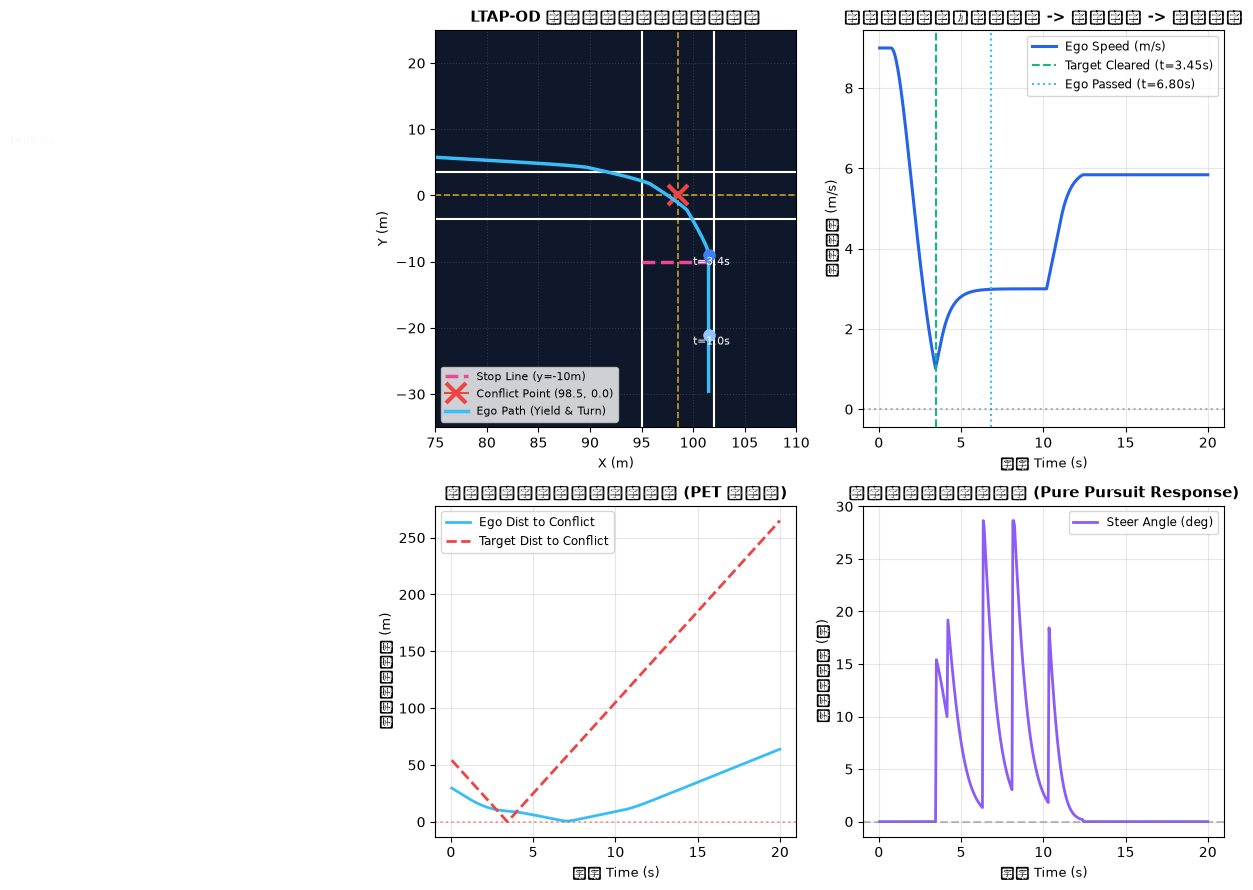

In [4]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import HTML, display

def plot_intersection_dashboard(res):
    """绘制四合一交叉口工程图表与鸟瞰轨迹"""
    traj = res['trajectory']
    times = [d['t'] for d in traj]
    ex = [d['ego_x'] for d in traj]
    ey = [d['ego_y'] for d in traj]
    ev = [d['ego_v'] for d in traj]
    steers = [d['steer'] * 180.0 / math.pi for d in traj]
    gaps = [d['gap'] for d in traj]

    fig = plt.figure(figsize=(14, 9))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1.0])

    # 1. 2D 交叉口俯视鸟瞰图 (BEV Snapshot)
    ax_bev = fig.add_subplot(gs[0, 0])
    ax_bev.set_facecolor('#0f172a')
    
    # 绘制道路与车道边界
    ax_bev.axvline(95.0, color='white', lw=1.5)
    ax_bev.axvline(102.0, color='white', lw=1.5)
    ax_bev.axvline(98.5, color='#fbbf24', linestyle='--', lw=1.2, alpha=0.8)

    ax_bev.axhline(-3.5, color='white', lw=1.5)
    ax_bev.axhline(3.5, color='white', lw=1.5)
    ax_bev.axhline(0.0, color='#fbbf24', linestyle='--', lw=1.2, alpha=0.8)

    # 停止线与冲突点
    ax_bev.plot([95.0, 102.0], [STOP_Y, STOP_Y], color='#ec4899', lw=2.5, linestyle='--', label='Stop Line (y=-10m)')
    ax_bev.plot([CX], [CY], marker='x', markersize=14, mew=3, color='#ef4444', label='Conflict Point (98.5, 0.0)')

    # 自车左转行驶轨迹
    ax_bev.plot(ex, ey, color='#38bdf8', lw=2.5, label='Ego Path (Yield & Turn)')
    
    # 标注重要快照时刻
    key_times = [1.0, res['t_tgt_pass'] if res['t_tgt_pass'] else 3.5, times[-1]]
    colors_ego = ['#93c5fd', '#3b82f6', '#1d4ed8']
    
    for idx, kt in enumerate(key_times):
        frame = min(traj, key=lambda d: abs(d['t'] - kt))
        ax_bev.plot(frame['ego_x'], frame['ego_y'], marker='o', color=colors_ego[idx], markersize=8)
        ax_bev.text(frame['ego_x'] - 1.5, frame['ego_y'] - 1.5, f"t={frame['t']:.1f}s", color='#f8fafc', fontsize=8)

    ax_bev.set_xlim(75, 110)
    ax_bev.set_ylim(-35, 25)
    ax_bev.set_xlabel('X (m)', fontsize=9.5)
    ax_bev.set_ylabel('Y (m)', fontsize=9.5)
    ax_bev.set_title('LTAP-OD 交叉口俯视轨迹与冲突几何', fontsize=11, fontweight='bold')
    ax_bev.grid(True, alpha=0.2, linestyle=':')
    ax_bev.legend(loc='lower left', fontsize=8)

    # 2. 速度变化曲线 (展示减速让行与出弯加速)
    ax_v = fig.add_subplot(gs[0, 1])
    ax_v.plot(times, ev, color='#2563eb', lw=2.2, label='Ego Speed (m/s)')
    if res['t_tgt_pass']:
        ax_v.axvline(res['t_tgt_pass'], color='#10b981', linestyle='--', label=f"Target Cleared (t={res['t_tgt_pass']:.2f}s)")
    if res['t_ego_pass']:
        ax_v.axvline(res['t_ego_pass'], color='#38bdf8', linestyle=':', label=f"Ego Passed (t={res['t_ego_pass']:.2f}s)")
    ax_v.axhline(0, color='gray', linestyle=':', alpha=0.6)
    ax_v.set_xlabel('时间 Time (s)', fontsize=9.5)
    ax_v.set_ylabel('自车速度 (m/s)', fontsize=9.5)
    ax_v.set_title('自车速度演变：减速让行 -> 驻车等待 -> 入弯加速', fontsize=11, fontweight='bold')
    ax_v.grid(True, alpha=0.3)
    ax_v.legend(fontsize=8.5)

    # 3. 两车到冲突点距离演进 (证实非重叠时空窗)
    ax_d = fig.add_subplot(gs[1, 0])
    d_ego_conflict = [math.hypot(d['ego_x'] - CX, d['ego_y'] - CY) for d in traj]
    d_tgt_conflict = [math.hypot(d['tgt_x'] - CX, d['tgt_y'] - CY) if d['tgt_x'] is not None else 0 for d in traj]
    ax_d.plot(times, d_ego_conflict, color='#38bdf8', lw=2.0, label='Ego Dist to Conflict')
    ax_d.plot(times, d_tgt_conflict, color='#ef4444', lw=2.0, linestyle='--', label='Target Dist to Conflict')
    ax_d.axhline(0, color='#ef4444', linestyle=':', alpha=0.5)
    ax_d.set_xlabel('时间 Time (s)', fontsize=9.5)
    ax_d.set_ylabel('到冲突点距离 (m)', fontsize=9.5)
    ax_d.set_title('两车到达冲突点时空窗口对比 (PET 时间窗)', fontsize=11, fontweight='bold')
    ax_d.grid(True, alpha=0.3)
    ax_d.legend(fontsize=8.5)

    # 4. Pure Pursuit 纯追踪前轮转角曲线
    ax_s = fig.add_subplot(gs[1, 1])
    ax_s.plot(times, steers, color='#8b5cf6', lw=2.0, label='Steer Angle (deg)')
    ax_s.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax_s.set_xlabel('时间 Time (s)', fontsize=9.5)
    ax_s.set_ylabel('前轮偏转角 (度)', fontsize=9.5)
    ax_s.set_title('纯追踪转弯转向角变化 (Pure Pursuit Response)', fontsize=11, fontweight='bold')
    ax_s.grid(True, alpha=0.3)
    ax_s.legend(fontsize=8.5)

    plt.tight_layout()
    plt.show()

def render_intersection_player(res):
    """生成并渲染轻量级原生 HTML5/Canvas 交互式 2D 十字路口动态回放器"""
    traj = res['trajectory']
    step = max(1, len(traj) // 100)
    sampled = traj[::step]
    if traj and sampled[-1] != traj[-1]:
        sampled.append(traj[-1])

    data_json = json.dumps([{
        't': round(d['t'], 2),
        'ex': round(d['ego_x'], 1),
        'ey': round(d['ego_y'], 1),
        'ev': round(d['ego_v'], 1),
        'eyaw': round(d['ego_yaw'], 2),
        'tx': round(d['tgt_x'] if d['tgt_x'] is not None else 98.5, 1),
        'ty': round(d['tgt_y'] if d['tgt_y'] is not None else -99.0, 1),
        'tv': round(d['tgt_v'] if d['tgt_v'] is not None else 0.0, 1),
        'gap': round(d['gap'], 1),
        'phase': d['phase']
    } for d in sampled])

    html_code = f"""
    <div id="a4_player_wrap" style="background: #0f172a; border-radius: 10px; padding: 14px; font-family: system-ui, sans-serif; color: #f8fafc; max-width: 820px; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.4); margin-top: 15px;">
      <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px;">
        <div style="font-weight: bold; font-size: 14px; display: flex; align-items: center; gap: 8px;">
          <span style="color: #38bdf8;">🚦 A4 LTAP-OD 交叉口动态交互回放器</span>
          <span id="a4_status" style="background: #334155; padding: 2px 8px; border-radius: 4px; font-size: 11px;">准备就绪</span>
        </div>
        <div style="font-size: 12px; color: #94a3b8; font-family: monospace;">
          t: <span id="a4_t" style="color: #f8fafc; font-weight: bold;">0.00</span>s | 
          自车: <span id="a4_v" style="color: #38bdf8; font-weight: bold;">0.0</span> m/s | 
          对向: <span id="a4_tv" style="color: #f87171; font-weight: bold;">0.0</span> m/s | 
          间距: <span id="a4_gap" style="color: #fbbf24; font-weight: bold;">0.0</span> m
        </div>
      </div>
      <canvas id="a4_canvas" width="790" height="280" style="width: 100%; height: 280px; background: #1e293b; border-radius: 6px; display: block;"></canvas>
      <div style="display: flex; align-items: center; gap: 10px; margin-top: 10px;">
        <button id="a4_btn_play" style="background: #2563eb; color: white; border: none; padding: 5px 14px; border-radius: 5px; cursor: pointer; font-size: 12px; font-weight: bold;">▶ 播放</button>
        <button id="a4_btn_reset" style="background: #475569; color: white; border: none; padding: 5px 12px; border-radius: 5px; cursor: pointer; font-size: 12px;">⏪ 复位</button>
        <input id="a4_slider" type="range" min="0" max="{len(sampled)-1}" value="0" style="flex: 1; accent-color: #38bdf8; cursor: pointer;">
        <select id="a4_speed" style="background: #334155; color: #f8fafc; border: 1px solid #475569; padding: 3px 6px; border-radius: 4px; font-size: 11px;">
          <option value="0.5">0.5x</option>
          <option value="1" selected>1.0x</option>
          <option value="2">2.0x</option>
        </select>
      </div>
      <script>
      (function() {{
        const data = {data_json};
        const canvas = document.getElementById('a4_canvas');
        if (!canvas) return;
        const ctx = canvas.getContext('2d');
        const slider = document.getElementById('a4_slider');
        const btnPlay = document.getElementById('a4_btn_play');
        const btnReset = document.getElementById('a4_btn_reset');
        const speedSel = document.getElementById('a4_speed');
        const txtStatus = document.getElementById('a4_status');
        const txtT = document.getElementById('a4_t');
        const txtV = document.getElementById('a4_v');
        const txtTV = document.getElementById('a4_tv');
        const txtGap = document.getElementById('a4_gap');
        let curIdx = 0;
        let isPlaying = false;
        let timer = null;

        // 世界坐标到画布像素坐标映射 (中心设在 X=98.5, Y=0.0)
        const CX_W = 98.5, CY_W = 0.0;
        const W = canvas.width, H = canvas.height;
        const ORIGIN_X = W * 0.62;
        const ORIGIN_Y = H * 0.45;
        const SCALE = 4.2;

        function toPx(x, y) {{
          return {{
            px: ORIGIN_X + (x - CX_W) * SCALE,
            py: ORIGIN_Y - (y - CY_W) * SCALE  // Y 轴反转 (屏幕下方向为正)
          }};
        }}

        function drawCar(x, y, yaw, color, text) {{
          const pt = toPx(x, y);
          ctx.save();
          ctx.translate(pt.px, pt.py);
          ctx.rotate(-yaw + Math.PI / 2);  // 转换航向角到屏幕角度
          ctx.fillStyle = color;
          ctx.strokeStyle = '#ffffff';
          ctx.lineWidth = 1.2;
          ctx.fillRect(-10, -20, 20, 40);
          ctx.strokeRect(-10, -20, 20, 40);
          ctx.fillStyle = '#ffffff';
          ctx.font = 'bold 9px sans-serif';
          ctx.textAlign = 'center';
          ctx.textBaseline = 'middle';
          ctx.fillText(text, 0, 0);
          ctx.restore();
        }}

        function renderFrame(idx) {{
          curIdx = idx;
          slider.value = idx;
          const d = data[idx];
          txtT.textContent = d.t.toFixed(2);
          txtV.textContent = d.ev.toFixed(1);
          txtTV.textContent = d.tv.toFixed(1);
          txtGap.textContent = d.gap.toFixed(1);

          if (d.phase === 'done' || (d.ex < 85 && d.ey > 4)) {{
            txtStatus.textContent = '✅ 安全通过交叉口';
            txtStatus.style.background = '#059669';
          }} else if (d.phase === 'turn') {{
            txtStatus.textContent = '🔄 纯追踪左转中 (Turn)';
            txtStatus.style.background = '#0284c7';
          }} else if (d.phase === 'hold') {{
            txtStatus.textContent = '⏸ 停止线驻车等待 (Hold)';
            txtStatus.style.background = '#d97706';
          }} else if (d.phase === 'yield') {{
            txtStatus.textContent = '⚠️ 让行减速中 (Yield)';
            txtStatus.style.background = '#ea580c';
          }} else {{
            txtStatus.textContent = '🔍 时空冲突评估 (Assess)';
            txtStatus.style.background = '#334155';
          }}

          ctx.clearRect(0, 0, W, H);

          // 1. 绘制十字路口道路沥青背景
          ctx.fillStyle = '#0f172a';
          // 南北向道路 (宽 16m)
          const roadN_pt = toPx(CX_W - 8.0, 35);
          ctx.fillRect(roadN_pt.px, 0, 16 * SCALE, H);
          // 东西向道路 (宽 16m)
          const roadW_pt = toPx(CX_W - 45, 8.0);
          ctx.fillRect(0, roadW_pt.py, W, 16 * SCALE);

          // 2. 车道虚线与道路边线
          ctx.strokeStyle = '#64748b';
          ctx.lineWidth = 1;
          ctx.setLineDash([8, 8]);
          // 南北中心线
          const p1 = toPx(CX_W, 35), p2 = toPx(CX_W, -35);
          ctx.beginPath(); ctx.moveTo(p1.px, 0); ctx.lineTo(p2.px, H); ctx.stroke();
          // 东西中心线
          const p3 = toPx(CX_W - 45, 0), p4 = toPx(CX_W + 20, 0);
          ctx.beginPath(); ctx.moveTo(0, p3.py); ctx.lineTo(W, p4.py); ctx.stroke();
          ctx.setLineDash([]);

          // 3. 停止线 Stop Line (y=-10m)
          const stopL = toPx(CX_W, -10.0), stopR = toPx(CX_W + 8.0, -10.0);
          ctx.strokeStyle = '#ec4899';
          ctx.lineWidth = 3;
          ctx.beginPath(); ctx.moveTo(stopL.px, stopL.py); ctx.lineTo(stopR.px, stopR.py); ctx.stroke();
          ctx.fillStyle = '#ec4899';
          ctx.font = '9px sans-serif';
          ctx.fillText('停止线 StopLine', stopR.px + 4, stopR.py + 3);

          // 4. 冲突点 Conflict Point (98.5, 0.0)
          const cp = toPx(CX_W, CY_W);
          ctx.strokeStyle = '#ef4444';
          ctx.lineWidth = 2.5;
          ctx.beginPath();
          ctx.moveTo(cp.px - 7, cp.py - 7); ctx.lineTo(cp.px + 7, cp.py + 7);
          ctx.moveTo(cp.px + 7, cp.py - 7); ctx.lineTo(cp.px - 7, cp.py + 7);
          ctx.stroke();
          ctx.fillStyle = '#fca5a5';
          ctx.fillText('冲突点', cp.px + 9, cp.py + 4);

          // 5. 绘制 Target 车辆 (直行红车)
          if (d.ty > -35 && d.ty < 40) {{
            drawCar(d.tx, d.ty, -Math.PI / 2, '#dc2626', 'Tgt');
          }}

          // 6. 绘制 Ego 车辆 (左转蓝车)
          drawCar(d.ex, d.ey, d.eyaw, '#2563eb', 'Ego');
        }}

        slider.addEventListener('input', (e) => {{
          renderFrame(parseInt(e.target.value));
        }});

        function playNext() {{
          if (!isPlaying) return;
          if (curIdx < data.length - 1) {{
            renderFrame(curIdx + 1);
            const speed = parseFloat(speedSel.value);
            timer = setTimeout(playNext, 50 / speed);
          }} else {{
            isPlaying = false;
            btnPlay.textContent = '▶ 播放';
          }}
        }}

        btnPlay.addEventListener('click', () => {{
          if (isPlaying) {{
            isPlaying = false;
            btnPlay.textContent = '▶ 播放';
            clearTimeout(timer);
          }} else {{
            if (curIdx >= data.length - 1) curIdx = 0;
            isPlaying = true;
            btnPlay.textContent = '⏸ 暂停';
            playNext();
          }}
        }});

        btnReset.addEventListener('click', () => {{
          isPlaying = false;
          btnPlay.textContent = '▶ 播放';
          clearTimeout(timer);
          renderFrame(0);
        }});

        renderFrame(0);
      }})();
      </script>
    </div>
    """
    display(HTML(html_code))

plot_intersection_dashboard(yield_res)
render_intersection_player(yield_res)


## 阶段五：参数调优实验室与对比实验 | Parameter Lab & Comparisons

### 💥 实验 5.1：让行控制 vs 激进盲目左转 (Naive) 硬核对比
运行不具备让行状态机的直接左转基准控制器（Naive），观测抢行时对向车与自车在十字路口中心发生的致命侧面 T-bone 碰撞。

### 📊 实验 5.2：让行时间裕度 $\tau_{\text{margin}}$ 敏感度分析
探究让行裕度对后侵入时间 PET 与等待延误的影响：
* 裕度较小（如 $0.5\,\text{s}$）：通行效率高，但 PET 逼近临界值，抗扰能力弱；
* 裕度较大（如 $2.5\,\text{s}$）：安全冗余充足，但路口等候时间延长。

### 🎯 实验 5.3：学生动手标定挑战 (Hands-on Calibration Challenge)
自主优化纯追踪前瞻距离与转弯目标车速，使左转轨迹兼顾循迹精度与乘员舒适度。


正在执行 对比实验：让行状态机 (Yield) vs 盲目强行左转 (Naive)...
[0.050] [info] act_start: true, delay: 0.00, 0.0500 > 0.0000, edge: rising
[0.050] [info] Trigger /------------------------------------------------
[0.050] [info] Group 0:
[0.050] [info] act_start: true
[0.050] [info] Trigger  ------------------------------------------------/
[0.050] [info] cruise_act standbyState -> startTransition -> runningState
[0.050] [info] cruise_group initState -> startTransition -> runningState
[0.050] [info] cruise_maneuver initState -> startTransition -> runningState
[0.050] [info] cruise_event initState -> initToStandbyTransition -> standbyState
[20.000] [info] Closing
esmini GIT REV: v3.10.0-0-06065f92
esmini GIT TAG: v3.10.0
esmini GIT BRANCH: tags/v3.10.0^0
esmini BUILD VERSION: 6442
[] [info] Ignoring missing default config: /opt/esmini/esmini/bin/../config.yml
[] [info] Loaded intersection.xosc
Unable to open log file log.txt
Unable to open log file log.txt
[2026-10-27 14:07:22]
Unable to open log file log.t

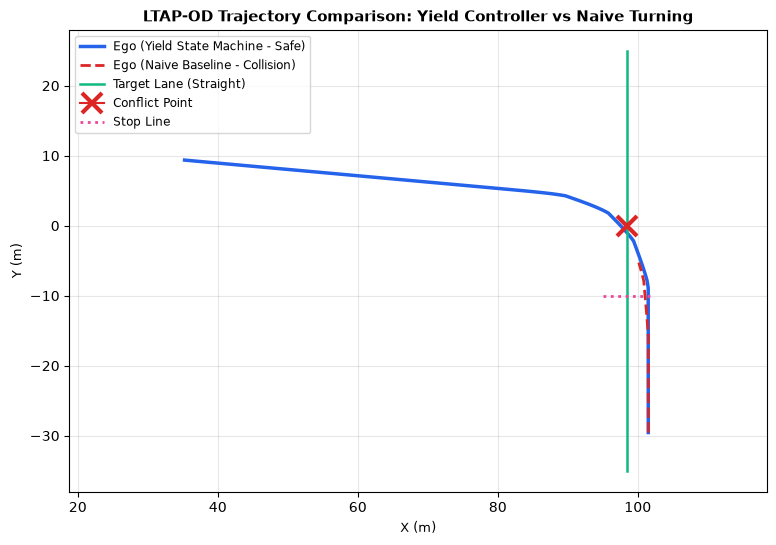


💡 [学生动手标定挑战] 寻找最优让行裕度与出弯车速：
尝试微调让行时间裕度 margin，观察 PET 的变化情况：
[0.050] [info] act_start: true, delay: 0.00, 0.0500 > 0.0000, edge: rising
[0.050] [info] Trigger /------------------------------------------------
[0.050] [info] Group 0:
[0.050] [info] act_start: true
[0.050] [info] Trigger  ------------------------------------------------/
[0.050] [info] cruise_act standbyState -> startTransition -> runningState
[0.050] [info] cruise_group initState -> startTransition -> runningState
[0.050] [info] cruise_maneuver initState -> startTransition -> runningState
[0.050] [info] cruise_event initState -> initToStandbyTransition -> standbyState
[3.650] [info] Closing
esmini GIT REV: v3.10.0-0-06065f92
esmini GIT TAG: v3.10.0
esmini GIT BRANCH: tags/v3.10.0^0
esmini BUILD VERSION: 6442
[] [info] Ignoring missing default config: /opt/esmini/esmini/bin/../config.yml
[] [info] Loaded intersection.xosc
Unable to open log file log.txt
Unable to open log file log.txt
[2026-10-27 14:07:23]
Unable to open

In [5]:
# ----------------------------------------------------
# 1. 让行控制 vs 激进盲目左转 (Naive) 对比实验
# ----------------------------------------------------
print("=" * 68)
print("正在执行 对比实验：让行状态机 (Yield) vs 盲目强行左转 (Naive)...")
naive_res = run_intersection_simulation(controller_type='naive')

_f = lambda v: f'{v:.2f}' if v is not None else 'N/A'
print("=" * 68)
print(f"{'评测维度':<16} | {'智能让行 (YieldController)':<20} | {'盲目左转 (NaiveBaseline)':<20}")
print("-" * 68)
print(f"{'是否发生碰撞':<16} | {'🛡️ 安全无碰撞' if not yield_res['is_collision'] else '💥 碰撞':<20} | {'🛡️ 安全无碰撞' if not naive_res['is_collision'] else '💥 T-bone 侧面相撞!':<20}")
print(f"{'后侵入时间 PET':<16} | {_f(yield_res['pet']) + ' s':<20} | {_f(naive_res['pet']) + ' s':<20}")
print(f"{'最小车间距':<16} | {yield_res['min_gap']:<20.2f}m | {naive_res['min_gap']:<20.2f}m")
print(f"{'冲突点 TTC 时空窗':<16} | {_f(yield_res['conflict_ttc']) + ' s':<20} | {_f(naive_res['conflict_ttc']) + ' s':<20}")
print("=" * 68)

# 叠画轨迹对比俯视图
plt.figure(figsize=(9, 6))
plt.plot([d['ego_x'] for d in yield_res['trajectory']], [d['ego_y'] for d in yield_res['trajectory']], 
         color='#2563eb', lw=2.5, label='Ego (Yield State Machine - Safe)')
plt.plot([d['ego_x'] for d in naive_res['trajectory']], [d['ego_y'] for d in naive_res['trajectory']], 
         color='#dc2626', lw=2.0, linestyle='--', label='Ego (Naive Baseline - Collision)')
plt.plot([98.5, 98.5], [-35, 25], color='#10b981', lw=1.8, label='Target Lane (Straight)')
plt.plot([CX], [CY], marker='x', markersize=14, mew=3, color='#dc2626', label='Conflict Point')
plt.plot([95.0, 102.0], [STOP_Y, STOP_Y], color='#ec4899', lw=2.0, linestyle=':', label='Stop Line')
plt.xlabel('X (m)', fontsize=9.5)
plt.ylabel('Y (m)', fontsize=9.5)
plt.title('LTAP-OD Trajectory Comparison: Yield Controller vs Naive Turning', fontsize=11, fontweight='bold')
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8.5)
plt.show()

# ----------------------------------------------------
# 2. 🎯 学生动手标定挑战 (Hands-on Calibration Challenge)
# ----------------------------------------------------
print("\n💡 [学生动手标定挑战] 寻找最优让行裕度与出弯车速：")
print("尝试微调让行时间裕度 margin，观察 PET 的变化情况：")

my_margin = 2.0    # 推荐调节范围: 1.0 ~ 2.5 秒
test_res = run_intersection_simulation(controller_type='yield', margin=my_margin)
print(f"👉 自定义裕度 ({my_margin}s) 测试结果: PET = {_f(test_res['pet'])}s, 最小间隙 = {test_res['min_gap']:.2f}m, 碰撞 = {test_res['is_collision']}")


## 阶段六：官方评分与结果归档 | Auto-Grading & Results

本阶段调用 IEV CloudLab 官方评测套件：
* **考核维度 1**：后侵入时间达标 (`pet_s >= 1.0s`, 权重 3)；
* **考核维度 2**：全流程安全无碰撞 (`collision == False`, 权重 2)；
* 评测结果自动保存为 JSON 文件，无缝对接平台成绩汇总系统与教师控制台。


In [6]:
import json
from common.evaluator import grade_metrics

# 1. 整理基线达标指标并落盘
save_dir = '/home/jovyan/labs/data/results'
record = {
    'experiment': 'A4_intersection_yield',
    'metrics': {
        'pet_s': round(yield_res['pet'], 2) if yield_res['pet'] is not None else 0.0,
        'collision': yield_res['is_collision']
    }
}

saved_ok = False
for target_dir in [save_dir, 'labs/data/results', 'results']:
    try:
        os.makedirs(target_dir, exist_ok=True)
        out_file = os.path.join(target_dir, 'A4_intersection_yield.json')
        with open(out_file, 'w', encoding='utf-8') as f:
            json.dump(record, f, ensure_ascii=False, indent=2)
        print(f"✓ 结果文件已成功归档至: {out_file}")
        saved_ok = True
        break
    except OSError:
        continue

if not saved_ok:
    print("ℹ️ 提示: 当前运行环境为只读挂载模式，跳过落盘，直接进入评测")

# 2. 调用平台官方评测器输出成绩单
eval_report = grade_metrics('A4_intersection_yield', record['metrics'])

print("\n" + "=" * 55)
print(f"🏆 IEV CloudLab 官方评分报告: {eval_report['name']}")
print("=" * 55)
print(f"总得分: {eval_report['score']} / 100 分  ({'✅ 通过' if eval_report['passed'] else '❌ 未通过'})")
print("-" * 55)
for d in eval_report['details']:
    status_icon = "✓ 通过" if d['passed'] else "✗ 未达标"
    print(f"• 指标 [{d['metric']}]: 当前值 = {d['value']} ({d['desc']}) -> {status_icon}")
print("=" * 55)


✓ 结果文件已成功归档至: labs/data/results/A4_intersection_yield.json

🏆 IEV CloudLab 官方评分报告: 交叉口让行
总得分: 100.0 / 100 分  (✅ 通过)
-------------------------------------------------------
• 指标 [pet_s]: 当前值 = 3.35 (PET后侵入时间>1.0s) -> ✓ 通过
• 指标 [collision]: 当前值 = False (无碰撞) -> ✓ 通过


## 阶段七：工程师实战经验与进阶挑战 | Reflection & Engineering Insights

### 🛠️ 量产工程痛点与思考

1. **A柱盲区与非视距 (A-Pillar Blind Spots & NLOS)**：
   * 在实车左转过程中，左前方的 A 柱会遮挡相当大角度的对向直行视线，纯视觉方案极易遗漏对向高速驶来的摩托车或小型车辆；
   * **工程落地解法**：量产车型多采用“前向长距雷达 + 宽视场角侧前角雷达”环视覆盖，或引入 V2X 车路协同（路侧感知设备 MEC 广播对向来车实时轨迹）。

2. **动态意图推断与博弈 (Dynamic Intent Inference & Game Theory)**：
   * 现实道路中，对向直行车可能减速让行，也可能加速抢行；
   * 更高阶的量产交互决策算法常采用高斯过程或动态博弈模型（Dynamic Game / MCTS），根据对向车在接近冲突区时的加速度微小变化实时推断其让行意图。

3. **后侵入时间 PET 的工业界基准**：
   * 行业大量自然驾驶数据（NDS）表明：$\text{PET} < 1.0\,\text{s}$ 会给车内驾驶员与对向来车带来强烈的险情恐慌，乘员心率与皮电反应显著飙升；
   * 因此在高级别自动驾驶标定中，常将防御性安全阈值设定在 $\text{PET} \ge 1.5 \sim 2.0\,\text{s}$。
